In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset name: Breast Cancer Wisconsin Diagnostic Dataset")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", np.unique(y))

Dataset name: Breast Cancer Wisconsin Diagnostic Dataset
Number of samples: 569
Number of features: 30
Target classes: [0 1]


In [3]:
print("Target names:", data.target_names)

print("\nFirst 10 target values:")
print(y[:10])

print("\nClass distribution:")
print(pd.Series(y).value_counts())

Target names: ['malignant' 'benign']

First 10 target values:
[0 0 0 0 0 0 0 0 0 0]

Class distribution:
1    357
0    212
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (455, 30)
Testing data shape: (114, 30)


In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [7]:
n_features = X_train_scaled.shape[1]

weights = np.zeros(n_features)
bias = 0.0

print("Number of weights:", len(weights))
print("Initial bias:", bias)

Number of weights: 30
Initial bias: 0.0


In [8]:
def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [9]:
def predict_probability(X, weights, bias):
    z = np.dot(X, weights) + bias
    return sigmoid(z)

In [10]:
def train_adam(
    X,
    y,
    learning_rate=0.01,
    epochs=100,
    beta1=0.9,
    beta2=0.999,
    epsilon=1e-8
):
    
    n_samples, n_features = X.shape
    
    weights = np.zeros(n_features)
    bias = 0.0
    
    # First moment estimates
    m_w = np.zeros(n_features)
    m_b = 0.0
    
    # Second moment estimates
    v_w = np.zeros(n_features)
    v_b = 0.0
    
    loss_history = []

    for epoch in range(1, epochs + 1):
        
        # Forward pass
        y_pred = predict_probability(
            X,
            weights,
            bias
        )
        
        # Calculate gradients
        dw = (1 / n_samples) * np.dot(
            X.T,
            (y_pred - y)
        )
        
        db = (1 / n_samples) * np.sum(
            y_pred - y
        )
        
        # Update biased first moment estimate
        m_w = beta1 * m_w + (1 - beta1) * dw
        m_b = beta1 * m_b + (1 - beta1) * db
        
        # Update biased second moment estimate
        v_w = beta2 * v_w + (1 - beta2) * (dw ** 2)
        v_b = beta2 * v_b + (1 - beta2) * (db ** 2)
        
        # Bias correction
        m_w_corrected = m_w / (1 - beta1 ** epoch)
        m_b_corrected = m_b / (1 - beta1 ** epoch)
        
        v_w_corrected = v_w / (1 - beta2 ** epoch)
        v_b_corrected = v_b / (1 - beta2 ** epoch)
        
        # Update weights and bias
        weights -= learning_rate * (
            m_w_corrected /
            (np.sqrt(v_w_corrected) + epsilon)
        )
        
        bias -= learning_rate * (
            m_b_corrected /
            (np.sqrt(v_b_corrected) + epsilon)
        )
        
        # Calculate loss
        y_pred_all = predict_probability(
            X,
            weights,
            bias
        )
        
        loss = compute_loss(y, y_pred_all)
        loss_history.append(loss)

    return weights, bias, loss_history

In [11]:
weights_adam, bias_adam, loss_adam = train_adam(
    X_train_scaled,
    y_train,
    learning_rate=0.01,
    epochs=100,
    beta1=0.9,
    beta2=0.999
)

print("Final Training Loss:", loss_adam[-1])

Final Training Loss: 0.09408463375263569


In [12]:
# Make predictions on the test data

y_test_prob_adam = predict_probability(
    X_test_scaled,
    weights_adam,
    bias_adam
)

# Convert probabilities to binary classes
y_test_pred_adam = (y_test_prob_adam >= 0.5).astype(int)

print("First 10 predicted probabilities:")
print(y_test_prob_adam[:10])

print("\nFirst 10 predicted classes:")
print(y_test_pred_adam[:10])

First 10 predicted probabilities:
[7.98560534e-01 2.86637120e-03 3.67792890e-02 9.81001904e-01
 9.95192401e-01 4.99873635e-07 1.29330488e-05 1.61404710e-01
 5.37859324e-01 9.84929065e-01]

First 10 predicted classes:
[1 0 0 1 1 0 0 0 1 1]


In [13]:
accuracy_adam = accuracy_score(y_test, y_test_pred_adam)
precision_adam = precision_score(y_test, y_test_pred_adam)
recall_adam = recall_score(y_test, y_test_pred_adam)
f1_adam = f1_score(y_test, y_test_pred_adam)

test_loss_adam = compute_loss(y_test, y_test_prob_adam)

print("Adam Results")
print("------------")
print(f"Test Loss: {test_loss_adam:.4f}")
print(f"Accuracy:  {accuracy_adam:.4f}")
print(f"Precision: {precision_adam:.4f}")
print(f"Recall:    {recall_adam:.4f}")
print(f"F1 Score:  {f1_adam:.4f}")

Adam Results
------------
Test Loss: 0.0807
Accuracy:  0.9912
Precision: 0.9861
Recall:    1.0000
F1 Score:  0.9930


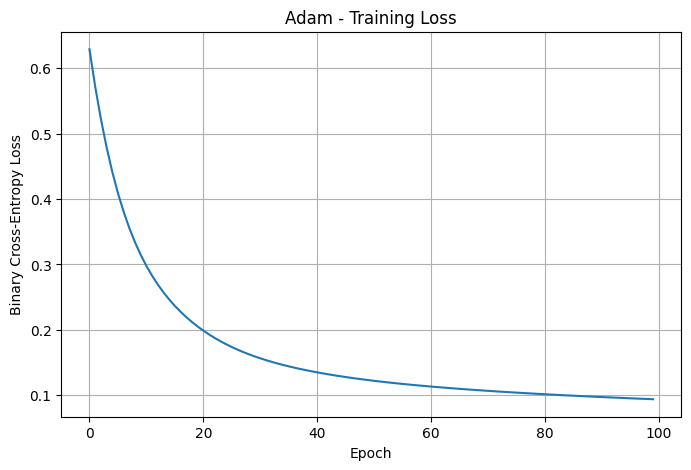

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(loss_adam)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Adam - Training Loss")
plt.grid(True)
plt.show()